In [12]:
import pandas as pd

In [13]:
data = pd.read_csv("Iris.csv")

In [14]:
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [15]:
data.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [16]:
data.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [18]:
data.shape

(150, 5)

In [19]:
data.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [21]:
data["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [22]:
data = data.drop(columns=["Id"], errors="ignore")

In [23]:
data.corr(numeric_only=True)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.117570,0.871754,0.817941
sepal_width,-0.117570,1.000000,-0.428440,-0.366126
petal_length,0.871754,-0.428440,1.000000,0.962865
petal_width,0.817941,-0.366126,0.962865,1.000000


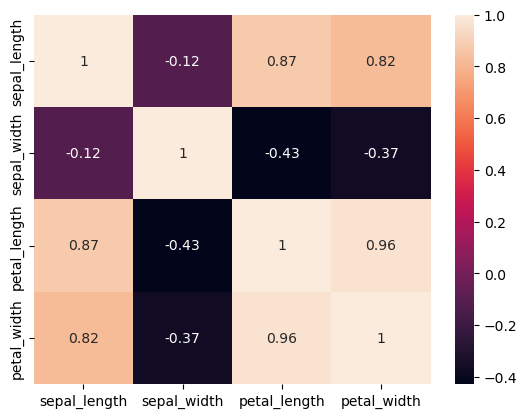

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data.corr(numeric_only=True), annot=True)
plt.show()

In [26]:
x = data.drop("species", axis=1)
y = data["species"]

In [27]:
x

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [28]:
y

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: species, Length: 150, dtype: object

In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [31]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

In [32]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
X_train_scaled

array([[-1.72156775, -0.33210111, -1.34572231, -1.32327558],
       [-1.12449223, -1.22765467,  0.41450518,  0.6517626 ],
       [ 1.14439475, -0.5559895 ,  0.58484978,  0.25675496],
       [-1.12449223,  0.11567567, -1.28894078, -1.45494479],
       [-0.40800161, -1.22765467,  0.13059752,  0.12508575],
       [ 0.54731923, -1.22765467,  0.69841284,  0.91510102],
       [-0.2885865 , -0.77987789,  0.24416059,  0.12508575],
       [ 0.54731923, -0.5559895 ,  0.75519438,  0.38842418],
       [ 2.21913069, -0.10821272,  1.3230097 ,  1.44177787],
       [ 2.21913069,  1.6828944 ,  1.66369889,  1.31010866],
       [ 2.09971558, -0.10821272,  1.60691736,  1.17843945],
       [ 0.18907392, -0.33210111,  0.41450518,  0.38842418],
       [-1.00507713, -2.34709662, -0.15331014, -0.26992188],
       [-0.04975629, -0.77987789,  0.18737906, -0.26992188],
       [-0.04975629, -1.00376628,  0.13059752, -0.00658346],
       [-1.36332244,  0.33956406, -1.23215924, -1.32327558],
       [-0.88566202,  1.

In [34]:
from sklearn.linear_model import LogisticRegression

In [35]:
model = LogisticRegression()

In [36]:
model.fit(X_train_scaled, y_train)

LogisticRegression()

In [37]:
tr_predicted = model.predict(X_train_scaled)
tr_predicted

array(['setosa', 'versicolor', 'versicolor', 'setosa', 'versicolor',
       'virginica', 'versicolor', 'versicolor', 'virginica', 'virginica',
       'virginica', 'versicolor', 'versicolor', 'versicolor',
       'versicolor', 'setosa', 'setosa', 'virginica', 'virginica',
       'setosa', 'versicolor', 'setosa', 'virginica', 'setosa',
       'versicolor', 'virginica', 'virginica', 'setosa', 'virginica',
       'setosa', 'setosa', 'versicolor', 'versicolor', 'setosa',
       'virginica', 'virginica', 'versicolor', 'versicolor', 'virginica',
       'virginica', 'setosa', 'versicolor', 'setosa', 'virginica',
       'setosa', 'setosa', 'virginica', 'setosa', 'setosa', 'setosa',
       'setosa', 'versicolor', 'virginica', 'versicolor', 'setosa',
       'virginica', 'versicolor', 'virginica', 'setosa', 'virginica',
       'setosa', 'versicolor', 'virginica', 'setosa', 'virginica',
       'versicolor', 'virginica', 'versicolor', 'versicolor', 'virginica',
       'setosa', 'setosa', 'setosa', '

In [38]:
from sklearn.metrics import accuracy_score

accuracy_score(y_train, tr_predicted)

0.9583333333333334

In [39]:
test_predicted = model.predict(X_test_scaled)
test_predicted

array(['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa',
       'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor',
       'virginica', 'virginica', 'virginica', 'versicolor', 'setosa',
       'setosa', 'setosa', 'versicolor', 'versicolor', 'virginica',
       'setosa', 'virginica', 'versicolor', 'versicolor', 'virginica',
       'virginica', 'versicolor', 'setosa', 'virginica', 'setosa'],
      dtype=object)

In [40]:
accuracy = accuracy_score(y_test, test_predicted)
accuracy

0.9333333333333333

In [41]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_predicted)
cm

array([[10,  0,  0],
       [ 0,  9,  1],
       [ 0,  1,  9]])

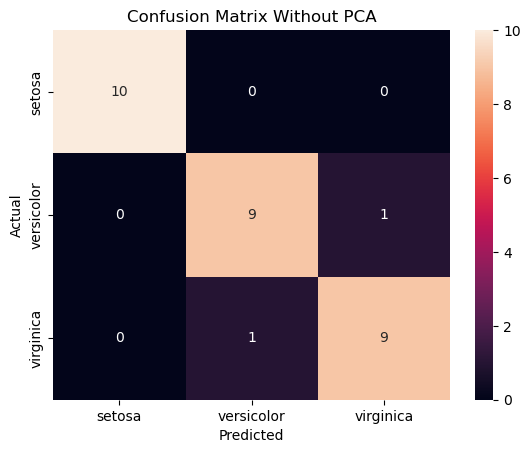

In [42]:
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=model.classes_,
            yticklabels=model.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Without PCA")
plt.show()

In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test, test_predicted))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [44]:
from sklearn.decomposition import PCA

In [45]:
pca = PCA(n_components=2)

In [46]:
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [47]:
X_train_pca

array([[-2.35430673, -1.03369922],
       [ 0.32811646, -1.48461375],
       [ 1.2290844 , -0.08852476],
       [-2.19452009, -0.41449679],
       [ 0.24248823, -1.27773347],
       [ 1.52294955, -0.87749328],
       [ 0.25815436, -0.81456565],
       [ 1.08813566, -0.28307828],
       [ 2.7816565 ,  0.80260248],
       [ 2.45214546,  2.47719638],
       [ 2.73500972,  0.75120347],
       [ 0.64451798, -0.20768998],
       [-0.17735004, -2.56577792],
       [ 0.12752389, -0.75913868],
       [ 0.30008117, -0.95247461],
       [-2.26948632, -0.27811494],
       [-2.31638839,  1.1510026 ],
       [ 1.96442486, -0.70771473],
       [ 1.33662596,  0.41860613],
       [-1.82655915,  0.44737164],
       [ 1.19203651, -0.91394324],
       [-2.35781737,  1.14379899],
       [ 2.32990455,  2.53829986],
       [-1.96744528, -0.57193611],
       [-0.02337536, -1.51777717],
       [ 1.4200781 , -0.03998037],
       [ 1.57165511, -0.41279836],
       [-2.04514806,  0.28260631],
       [ 0.95404926,

In [48]:
print("Before PCA:", X_train_scaled.shape)
print("After PCA:", X_train_pca.shape)

Before PCA: (120, 4)
After PCA: (120, 2)


In [49]:
pca.explained_variance_ratio_

array([0.72677234, 0.23066667])

In [50]:
pca.explained_variance_ratio_.sum() * 100

np.float64(95.74390106545361)

In [51]:
pd.DataFrame(pca.components_,
             columns=x.columns,
             index=["PC1", "PC2"])

,sepal_length,sepal_width,petal_length,petal_width
PC1,0.526793,-0.253072,0.581869,0.565572
PC2,0.348139,0.934708,0.026894,0.066308


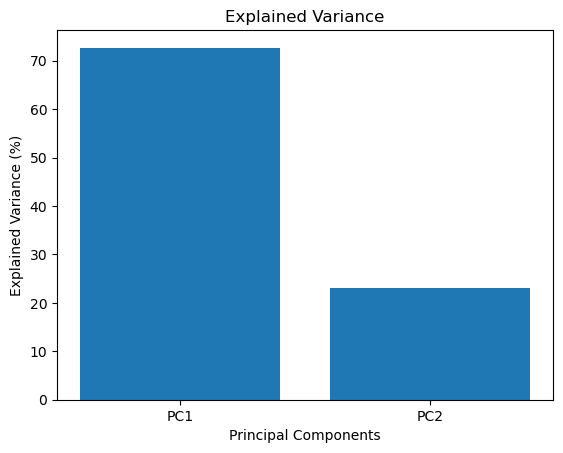

In [52]:
plt.bar(["PC1", "PC2"], pca.explained_variance_ratio_ * 100)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance")
plt.show()

In [53]:
pca_data = pd.DataFrame(X_train_pca, columns=["PC1", "PC2"])
pca_data["Species"] = y_train.values

pca_data.head()

,PC1,PC2,Species
0,-2.354307,-1.033699,setosa
1,0.328116,-1.484614,virginica
2,1.229084,-0.088525,versicolor
3,-2.194520,-0.414497,setosa
4,0.242488,-1.277733,versicolor


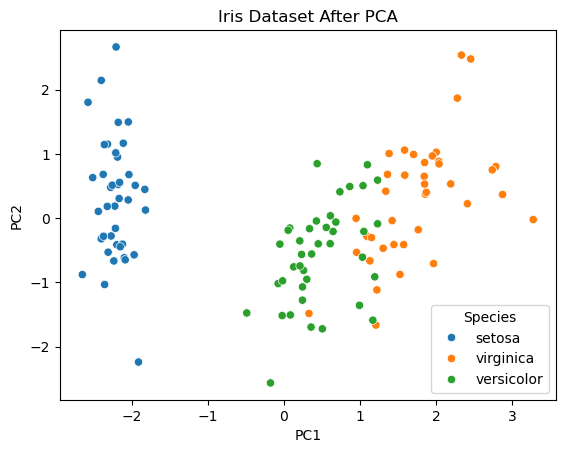

In [54]:
sns.scatterplot(data=pca_data, x="PC1", y="PC2", hue="Species")

plt.title("Iris Dataset After PCA")
plt.show()

In [55]:
model_pca = LogisticRegression()

In [56]:
model_pca.fit(X_train_pca, y_train)

LogisticRegression()

In [57]:
model_pca.fit(X_train_pca, y_train)

LogisticRegression()

In [58]:
tr_predicted_pca = model_pca.predict(X_train_pca)
tr_predicted_pca

array(['setosa', 'versicolor', 'virginica', 'setosa', 'versicolor',
       'virginica', 'versicolor', 'virginica', 'virginica', 'virginica',
       'virginica', 'versicolor', 'versicolor', 'versicolor',
       'versicolor', 'setosa', 'setosa', 'virginica', 'virginica',
       'setosa', 'virginica', 'setosa', 'virginica', 'setosa',
       'versicolor', 'virginica', 'virginica', 'setosa', 'versicolor',
       'setosa', 'setosa', 'versicolor', 'versicolor', 'setosa',
       'virginica', 'virginica', 'versicolor', 'versicolor', 'virginica',
       'versicolor', 'setosa', 'virginica', 'setosa', 'virginica',
       'setosa', 'setosa', 'virginica', 'setosa', 'setosa', 'setosa',
       'setosa', 'versicolor', 'virginica', 'versicolor', 'setosa',
       'versicolor', 'versicolor', 'virginica', 'setosa', 'virginica',
       'setosa', 'versicolor', 'virginica', 'setosa', 'versicolor',
       'versicolor', 'virginica', 'versicolor', 'versicolor', 'virginica',
       'setosa', 'setosa', 'setosa', '

In [59]:
accuracy_score(y_train, tr_predicted_pca)

0.9333333333333333

In [60]:
test_predicted_pca = model_pca.predict(X_test_pca)
test_predicted_pca

array(['setosa', 'versicolor', 'versicolor', 'versicolor', 'setosa',
       'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor',
       'virginica', 'virginica', 'virginica', 'versicolor', 'setosa',
       'setosa', 'setosa', 'versicolor', 'versicolor', 'versicolor',
       'setosa', 'virginica', 'versicolor', 'virginica', 'virginica',
       'virginica', 'versicolor', 'setosa', 'virginica', 'setosa'],
      dtype=object)

In [61]:
accuracy_pca = accuracy_score(y_test, test_predicted_pca)
accuracy_pca

0.9

In [62]:
cm_pca = confusion_matrix(y_test, test_predicted_pca)
cm_pca

array([[10,  0,  0],
       [ 0,  9,  1],
       [ 0,  2,  8]])

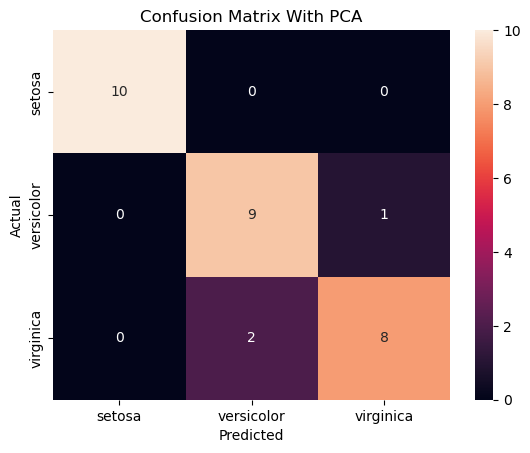

In [63]:
sns.heatmap(cm_pca, annot=True, fmt="d",
            xticklabels=model_pca.classes_,
            yticklabels=model_pca.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix With PCA")
plt.show()

In [64]:
print(classification_report(y_test, test_predicted_pca))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [66]:
print("Without PCA:", accuracy)
print("With PCA:", accuracy_pca)

Without PCA: 0.9333333333333333
With PCA: 0.9


In [67]:
precision = precision_score(y_test, test_predicted, average="macro")
precision_pca = precision_score(y_test, test_predicted_pca, average="macro")

print(precision)
print(precision_pca)

0.9333333333333332
0.9023569023569024


In [68]:
recall = recall_score(y_test, test_predicted, average="macro")
recall_pca = recall_score(y_test, test_predicted_pca, average="macro")

print(recall)
print(recall_pca)

0.9333333333333332
0.9


In [69]:
f1 = f1_score(y_test, test_predicted, average="macro")
f1_pca = f1_score(y_test, test_predicted_pca, average="macro")

print(f1)
print(f1_pca)

0.9333333333333332
0.899749373433584


In [70]:
result = pd.DataFrame({
    "Model": ["Without PCA", "With PCA"],
    "Features": [4, 2],
    "Accuracy": [accuracy, accuracy_pca],
    "Precision": [precision, precision_pca],
    "Recall": [recall, recall_pca],
    "F1 Score": [f1, f1_pca]
})

result

,Model,Features,Accuracy,Precision,Recall,F1 Score
0,Without PCA,4,0.933333,0.933333,0.933333,0.933333
1,With PCA,2,0.900000,0.902357,0.900000,0.899749


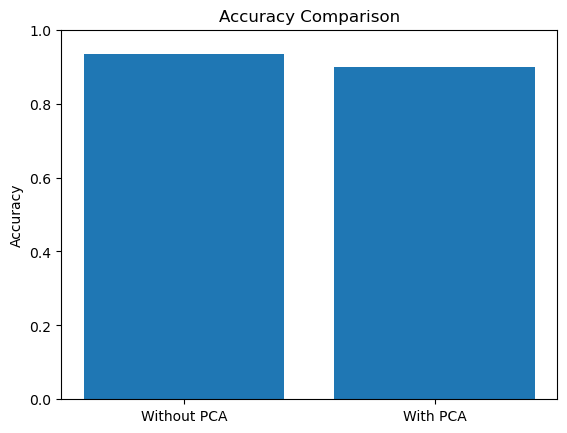

In [71]:
plt.bar(["Without PCA", "With PCA"], [accuracy, accuracy_pca])

plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.ylim(0, 1)
plt.show()

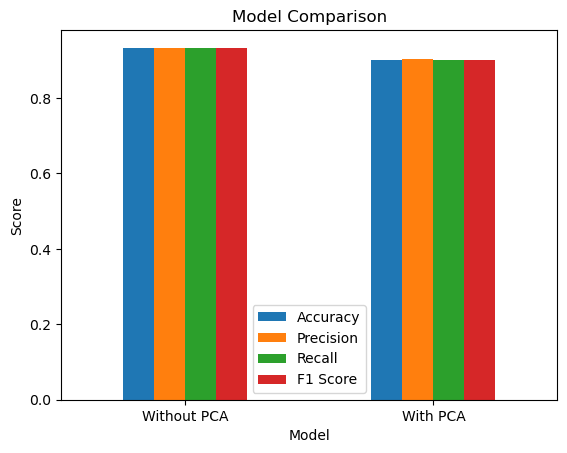

In [72]:
result.set_index("Model").drop("Features", axis=1).plot(kind="bar")

plt.ylabel("Score")
plt.title("Model Comparison")
plt.xticks(rotation=0)
plt.show()

In [73]:
reduction = (1 - X_train_pca.shape[1] / X_train.shape[1]) * 100

print("Feature Reduction:", reduction, "%")

Feature Reduction: 50.0 %


In [74]:
print("Original Features:", X_train.shape[1])
print("Principal Components:", X_train_pca.shape[1])
print("Variance Retained:", pca.explained_variance_ratio_.sum() * 100)
print("Accuracy Without PCA:", accuracy)
print("Accuracy With PCA:", accuracy_pca)

Original Features: 4
Principal Components: 2
Variance Retained: 95.74390106545361
Accuracy Without PCA: 0.9333333333333333
Accuracy With PCA: 0.9
